In [1]:
# Interactive Figure
%matplotlib widget 

Matplotlib is building the font cache; this may take a moment.


In [2]:
import time
import numpy as np
from matplotlib import pyplot as plt
from qualang_tools.units import unit
u = unit(coerce_to_integer=True)
from qm.qua import *
from qm import SimulationConfig
from qualang_tools.loops import from_array
import QM

2026-03-03 11:04:07,358 - qm - INFO     - Starting session: 4626d012-cb25-49da-b5cf-b48b67726ab9


# Send pulses and observe them

In [3]:
# This block is using QUA directives which are compiled to the FPGA
with program() as prog:
    # Variable declaration
    adc_stream = declare_stream(adc_trace=True)
    # Start measurement
    measure('readout', 'scope', adc_stream=adc_stream)
    # Pulse sequence
    play('pulse','qubit')
    wait(24*u.ns)
    play('pulse','qubit')

    # Select data to be sent to the client 
    with stream_processing():
        adc_stream.input1().save('adc_1')
        adc_stream.input2().save('adc_2')

In [4]:
# Run the code and fetch results
job = QM.Job(prog)

Button(description='Abort', style=ButtonStyle())

Output(outputs=({'output_type': 'stream', 'name': 'stdout', 'text': 'Sending job to qm-1699244607963...'}, {'o…

HTML(value='')

In [5]:
# Fetch results
adc_1, adc_2 = job.get_results('adc_1','adc_2')

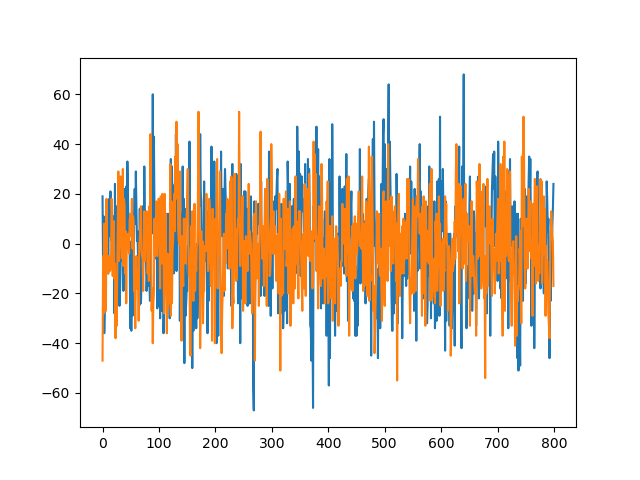

In [6]:
# Plot
readout_len = 800 # in ns from the config
t = np.arange(readout_len)
fig,ax=plt.subplots()
ax.plot(t,adc_1,t,adc_2)

# Simulate QUA code

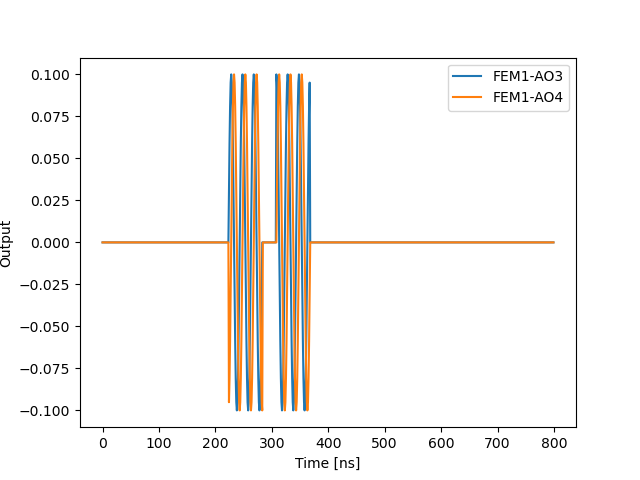

In [7]:
plt.figure()
# Simulates the QUA program for the specified duration
simulation_config = SimulationConfig(duration=readout_len//4)  # In clock cycles = 4ns
# Simulate blocks python until the simulation is done
config = QM.get_config(full=True)
job = QM.qmm.simulate(config, prog, simulation_config)
# Get the simulated samples
samples = job.get_simulated_samples()
# Plot the simulated samples
samples.con1.plot()
plt.show()

# Display QM configuration

In [8]:
QM.show_config()

# Exercises
- Link to the Quantum Machines documentation:  [https://docs.quantum-machines.co/latest/](https://docs.quantum-machines.co/latest/)
- Read the documentation on the [`play`](https://docs.quantum-machines.co/latest/docs/API_references/qua/dsl_main/#for_docs.dsl.play) command

## Exercise 1: Phase Evolution
- Play two pulses one after the other with no waiting time. Are the traces continuous? Why?
- Dephase the second pulse by $\pi/2$ using a [`frame_rotation`](https://docs.quantum-machines.co/latest/docs/API_references/qua/dsl_main/#for_docs.dsl.frame_rotation) command applied to the `qubit` element. Add a delay between the pulses again and observe the phase evolution.

## Exercise 2: Pulse Timing
- Change the pulse duration to 100 ns using the `duration` keyword in the [`play`](https://docs.quantum-machines.co/latest/docs/API_references/qua/dsl_main/#for_docs.dsl.play) command.
- Read the documentation on [timing](https://docs.quantum-machines.co/latest/docs/Guides/timing_in_qua/)
- Modify the sequence to create two pulses separated by 500 ns

## Exercise 3: Arbitrary Pulses and Amplitude Tuning
- In the [`play`](https://docs.quantum-machines.co/latest/docs/API_references/qua/dsl_main/#for_docs.dsl.play) command, replace `pulse` with `gaussian` and observe the results (remove the `duration` parameter if present). You can look in the `config_00.py` file to see how arbitrary pulses are constructed.
- Modify the pulse amplitude using [`amp`](https://docs.quantum-machines.co/latest/docs/API_references/qua/dsl_main/#for_docs.dsl.amp) in the [`play`](https://docs.quantum-machines.co/latest/docs/API_references/qua/dsl_main/#for_docs.dsl.play) command.